In [1]:

import numpy as np
import polars as pl
import pandas as pd
import gsd.hoomd
import schmeud
import schmeud._schmeud as schmeud_rs
from schmeud._schmeud import statics
from schmeud import ml
from tqdm import tqdm

import glob
import os
import pathlib
import pickle
import signac
import freud
from numba import njit

from dataclasses import dataclass
from collections import defaultdict

import matplotlib.pyplot as plt
from scipy import stats
from typing import Union
from matplotlib import colors, cm

In [2]:
from monk import workflow, utils

In [3]:
cwd = pathlib.Path(os.getcwd())
parent = cwd.parent.parent / "config.yaml"
config = workflow.get_config(parent.as_posix())

In [4]:
PROJECT: signac.Project = signac.get_project(root=config['root'])

In [5]:
for job in PROJECT.find_jobs(filter={"prep": "HTL"}):
    print(job.id)

634e14bc75836df75158fb15f379d8bb
6976a7c10ada4159010403f8027f3ea5
1083a2a09eec2c6cf215ebc7a9706cac
ecce68c50e28a33684826f28780bf6e9
cfa1e4c0007fd65d020f809715a6f0b4
9158e73b2e4c9fd1a565e1e5d1bc3af5


In [6]:
for job in PROJECT.find_jobs(filter={"prep": "ESL"}):
    print(job.id)

c6d7afd0de62bfa16d05da47815227eb
09d3dccc56f1fa9330b57901cd232ab7
1d0fe2ba44a6f635f5504dcbcee0ebc9
a8f2c249ed85533b56b0729b7ab96d18
7ec2f6aca035e69077eab24383a21cb6
bf92a185d043ce3ef666e05e427c7e76


In [ ]:
cd ""

In [66]:
id = "a8f2c249ed85533b56b0729b7ab96d18"
id = "9158e73b2e4c9fd1a565e1e5d1bc3af5"

with PROJECT.open_job(id=id) as job:
    
    visualize_exp = job.fn("aqs_linear_experiments/max-shear-0.15/temp-0.0000/traj_period-0.001_more-fire.gsd")

    traj = gsd.hoomd.open(name=visualize_exp)

    start = 0
    osnap = traj[start]
    opos = osnap.particles.position
    # end = len(traj) - 1
    end = 150
    snap = traj[end]

    obox = osnap.configuration.box
    box = snap.configuration.box

    query = freud.locality.AABBQuery.from_system(osnap)
    nlist = query.query(opos, {"num_neighbors": 20, "exclude_ii": True}).toNeighborList()

    d2min = schmeud_rs.dynamics.d2min_frame(
            osnap.particles.position[:, :2],
            snap.particles.position[:, :2],
            nlist.query_point_indices,
            nlist.point_indices,
            (obox, box),
        )

In [93]:
def plot_d2min_field(pos, d2min, norm=None, cmap=None, ax=None, annotation=None, subtitle=None, spines=False, L=None, s=1, alpha=1.0):
    if ax is None:
        fig, ax = plt.subplots(dpi=100)

    if cmap is None:
        cmap = cm.viridis
    ax.set_aspect("equal")
    h = ax.scatter(pos[:, 0], pos[:, 1], c=d2min, cmap=cmap, s=s, norm=norm, alpha=alpha)
    # remove all axis labels
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    # remove frame boundary
    if not spines:
        for spine in ax.spines.values():
            spine.set_visible(False)
    if annotation is not None:
        ax.text(-0.0, 1.0, annotation, transform=ax.transAxes, 
                size=20, weight='bold')
    if subtitle is not None:
        ax.set_title(**subtitle)

    if L is not None:
        if isinstance(L, list):
            ax.set_xlim(-L[0]/2, L[0]/2)
            ax.set_ylim(-L[1]/2, L[1]/2)
        else:
            ax.set_xlim(-L/2, L/2)
            ax.set_ylim(-L/2, L/2)
    # plt.show()
    return h

In [68]:
box

array([1.6524728e+02, 1.6524728e+02, 0.0000000e+00, 1.5000001e-01,
       0.0000000e+00, 0.0000000e+00], dtype=float32)

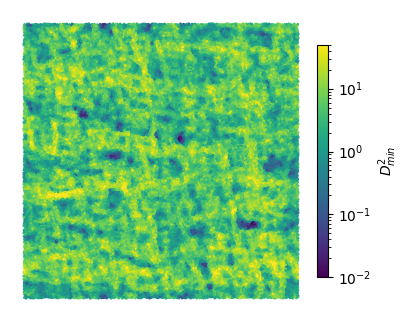

In [83]:
fig, ax = plt.subplots(dpi=100)
norm = colors.LogNorm(vmin=1e-2, vmax=50)
# norm = colors.Normalize(vmin=0, vmax=15)
h = plot_d2min_field(osnap.particles.position, d2min, ax=ax, norm=norm)
# make colorbar a bit smaller
plt.colorbar(h, label=r"$D^2_{min}$", fraction=0.025, pad=0.01)

In [97]:
with PROJECT.open_job(id="634e14bc75836df75158fb15f379d8bb") as job:
    
    visualize_exp = job.fn("aqs_linear_experiments/max-shear-0.40/temp-0.0000/traj_period-0.001_more-fire.gsd")

    traj = gsd.hoomd.open(name=visualize_exp)

    outputs = []

    
    
    start = 0
    osnap = traj[start]
    opos = osnap.particles.position
    query = freud.locality.AABBQuery.from_system(osnap)
    nlist = query.query(opos, {"num_neighbors": 20, "exclude_ii": True}).toNeighborList()
    obox = osnap.configuration.box
    pbar = tqdm(total=len(traj))
    for i in range(1, len(traj)):
        
        
        # end = len(traj) - 1
        # end = 150
        snap = traj[i]

        
        box = snap.configuration.box

        

        d2min = schmeud_rs.dynamics.d2min_frame(
                osnap.particles.position[:, :2],
                snap.particles.position[:, :2],
                nlist.query_point_indices,
                nlist.point_indices,
                (obox, box),
            )
        outputs.append(d2min)
        pbar.update(1)

100%|██████████| 400/400 [05:37<00:00,  1.19it/s]


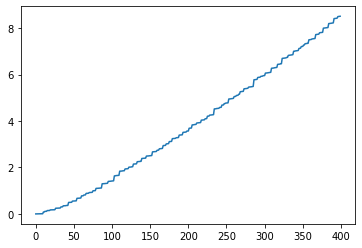

In [98]:
plt.plot(np.mean(outputs, axis=1))

In [84]:
# clear outputs folder
outputs1 = pathlib.Path("outputs")

for f in outputs1.glob("*"):
    f.unlink()

Starting


100%|██████████| 400/400 [03:58<00:00,  1.66it/s]

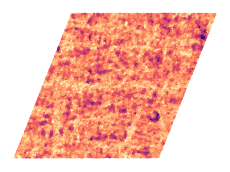

In [99]:
fig = plt.figure(frameon=False)
ax = plt.Axes(fig, [0., 0., 1., 1.])
ax.set_axis_off()
fig.add_axes(ax)
fig.set_size_inches(3, 3)
norm = colors.LogNorm(vmin=1e-2, vmax=50)
# norm = colors.Normalize(vmin=0, vmax=10)
cmap = cm.magma
# idx = 199
# h = plot_d2min_field(traj[50].particles.position, outputs[50], ax=ax, norm=norm, cmap=cmap, spines=False, L=box[0]*1.1)
# make colorbar a bit smaller
# plt.colh = plot_d2min_field(traj[50].particles.position, outputs[50], ax=ax,
# norm=norm, cmap=cmap, spines=False, L=box[0]*1.1)orbar(h,
# label=r"$D^2_{min}$", fraction=0.025, pad=0.01)
print("Starting")

pbar = tqdm(total=len(outputs))
for idx in range(len(outputs))[:]:
    plt.cla()
    h = plot_d2min_field(traj[idx].particles.position, outputs[idx], ax=ax, norm=norm, cmap=cmap, spines=False, L=[box[0]*1.5, box[1]*1.1])
    plt.savefig(f"outputs/{idx:04d}.png", dpi=300)
    pbar.update(1)

In [100]:
import ffmpeg

ffmpeg.input("outputs/%04d.png", framerate=20).output("40%-HTL-simple-shear.mp4").run()

ffmpeg version 4.2.2 Copyright (c) 2000-2019 the FFmpeg developers
  built with gcc 7.3.0 (crosstool-NG 1.23.0.449-a04d0)
  configuration: --prefix=/tmp/build/80754af9/ffmpeg_1587154242452/_h_env_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placehold_placeho --cc=/tmp/build/80754af9/ffmpeg_1587154242452/_build_env/bin/x86_64-conda_cos6-linux-gnu-cc --disable-doc --enable-avresample --enable-gmp --enable-hardcoded-tables --enable-libfreetype --enable-libvpx --enable-pthreads --enable-libopus --enable-postproc --enable-pic --enable-pthreads --enable-shared --enable-static --enable-version3 --enable-zlib --enable-libmp3lame --disable-nonfree --enable-gpl --enable-gnutls --disable-openssl --enable-libopenh264 --enable-libx264
  libavutil      56. 31.100 / 56. 31.100
  libavcodec     58. 54.100 / 58. 54.100
  libavformat    58. 29.100 / 58. 29.100


(None, None)